# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LogisticRegression

In [35]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [36]:
df = df.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'species'])
print(df.shape)
df.head()

(342, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [37]:
df['species'] = pd.Categorical(df['species']).codes
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,0,Torgersen,39.1,18.7,181.0,3750.0,Male
1,0,Torgersen,39.5,17.4,186.0,3800.0,Female
2,0,Torgersen,40.3,18.0,195.0,3250.0,Female
4,0,Torgersen,36.7,19.3,193.0,3450.0,Female
5,0,Torgersen,39.3,20.6,190.0,3650.0,Male


In [38]:
# Twoje rozwiązanie
df = sns.load_dataset("penguins")
df = df.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'species'])
df['species'] = pd.Categorical(df['species']).codes

X = df[['bill_length_mm', 'bill_depth_mm']].values
y = df['species'].values

X_train_val, X_te_arr, y_train_val, y_te_arr = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

X_tr_arr, X_va_arr, y_tr_arr, y_va_arr = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    stratify=y_train_val,
    random_state=42,
)

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr_arr)
X_va_scaled = scaler.transform(X_va_arr)
X_te_scaled = scaler.transform(X_te_arr)

X_tr = torch.tensor(X_tr_scaled, dtype=torch.float32)
X_va = torch.tensor(X_va_scaled, dtype=torch.float32)
X_te = torch.tensor(X_te_scaled, dtype=torch.float32)

y_tr = torch.tensor(y_tr_arr, dtype=torch.long)
y_va = torch.tensor(y_va_arr, dtype=torch.long)
y_te = torch.tensor(y_te_arr, dtype=torch.long)

print(f"Treningowy:  X={X_tr.shape}, y={y_tr.shape}")
print(f"Walidacyjny: X={X_va.shape}, y={y_va.shape}")
print(f"Testowy:     X={X_te.shape}, y={y_te.shape}")

Treningowy:  X=torch.Size([204, 2]), y=torch.Size([204])
Walidacyjny: X=torch.Size([69, 2]), y=torch.Size([69])
Testowy:     X=torch.Size([69, 2]), y=torch.Size([69])


In [39]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [40]:
# Twoje rozwiązanie
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

loss0 = loss_fn(model(X_tr), y_tr).item()
p0 = torch.softmax(model(X_tr[:3]), dim=1)
print(loss0)
print(p0)

1.5297863483428955
tensor([[0.1938, 0.5522, 0.2539],
        [0.3298, 0.3845, 0.2857],
        [0.4144, 0.2371, 0.3485]], grad_fn=<SoftmaxBackward0>)


In [41]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

Funkcja straty dla rozkładu jednorodnego wynosi ~1.10. Wartość loss0 jest bardzo blisko tej liczby, ponieważ przed rozpoczęciem uczenia wagi i obciążenia liniowego modelu są inicjalizowane losowo wartościami bliskimi zeru. Skutkuje to wyjściami z modelu o podobnych wartościach, co daje rozkład prawdopodobieństwa zbliżony do równomiernego.

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

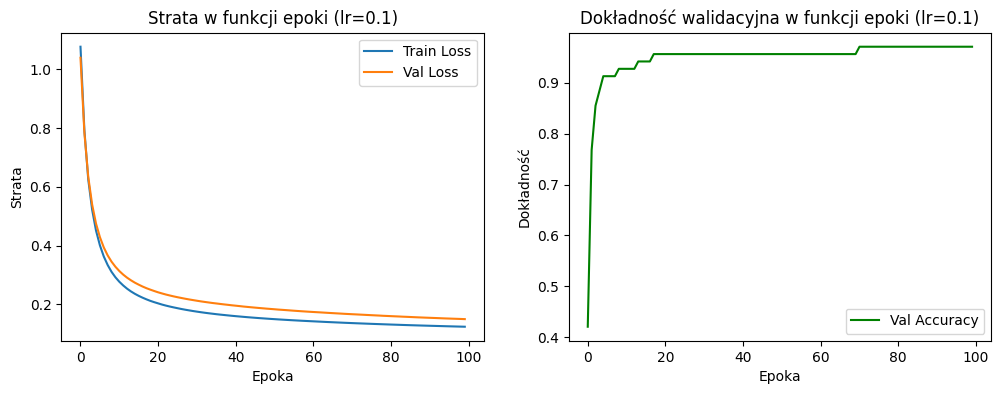

In [42]:
# Twoje rozwiązanie
def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
    torch.manual_seed(seed)

    model_loc = nn.Linear(X.shape[1], 3)
    loss_fn_loc = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model_loc.parameters(), lr=lr)

    dataset = TensorDataset(X, y_tr)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    historia = {"train loss": [], "val loss": [], "val acc": []}

    for epoch in range(epochs):
        model_loc.train()
        for b_X, b_y in loader:
            optimizer.zero_grad()
            out = model_loc(b_X)
            loss = loss_fn_loc(out, b_y)
            loss.backward()
            optimizer.step()

        model_loc.eval()
        with torch.no_grad():
            tr_loss = loss_fn_loc(model_loc(X), y_tr).item()
            va_out = model_loc(X_val)
            va_loss = loss_fn_loc(va_out, y_va).item()
            va_preds = torch.argmax(va_out, dim=1)
            va_acc = (va_preds == y_va).float().mean().item()

        historia["train loss"].append(tr_loss)
        historia["val loss"].append(va_loss)
        historia["val acc"].append(va_acc)

    return model_loc, historia

model_01, hist_01 = train(lr=0.1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_01["train loss"], label="Train Loss")
axes[0].plot(hist_01["val loss"], label="Val Loss")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Strata")
axes[0].set_title("Strata w funkcji epoki (lr=0.1)")
axes[0].legend()

axes[1].plot(hist_01["val acc"], label="Val Accuracy", color="green")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Dokładność")
axes[1].set_title("Dokładność walidacyjna w funkcji epoki (lr=0.1)")
axes[1].legend()
plt.show()

In [43]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

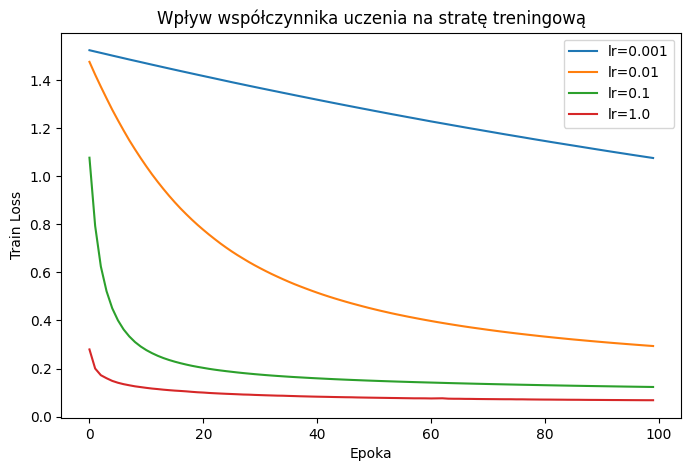

       val loss   val acc
0.001  1.038211  0.420290
0.010  0.329397  0.927536
0.100  0.149183  0.971014
1.000  0.072390  0.971014


In [44]:
# Twoje rozwiązanie
lrs = [0.001, 0.01, 0.1, 1.0]
wyniki_dict = {}

plt.figure(figsize=(8, 5))

for lr in lrs:
    _, hist = train(lr=lr)
    plt.plot(hist["train loss"], label=f"lr={lr}")
    wyniki_dict[lr] = {
        "val loss": hist["val loss"][-1],
        "val acc": hist["val acc"][-1]
    }

plt.xlabel("Epoka")
plt.ylabel("Train Loss")
plt.title("Wpływ współczynnika uczenia na stratę treningową")
plt.legend()
plt.show()

wyniki_lr = pd.DataFrame.from_dict(wyniki_dict, orient="index")
print(wyniki_lr)

In [45]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

Dla lr = 0.001 krok gradientu jest zbyt mały, przez co spadek funkcji starty zachodzi bardzo powoli i model po 100 epokach nie zdążył osiągnąć zbieżność. Wybieram lr = 0.1 na podstawie najniższej wartości val loss oraz wysokiej stabilości na zbiorze walidacyjnym


---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

In [46]:
# Twoje rozwiązanie
X_tr_raw = torch.tensor(X_tr_arr, dtype=torch.float32)
X_va_raw = torch.tensor(X_va_arr, dtype=torch.float32)

_, hist_raw = train(lr=0.1, X=X_tr_raw, X_val=X_va_raw)

print(f"Bez standaryzacji - val loss: {hist_raw['val loss'][-1]:.4f}, val acc: {hist_raw['val acc'][-1]:.4f}")
print(f"Ze standaryzacją  - val loss: {hist_01['val loss'][-1]:.4f}, val acc: {hist_01['val acc'][-1]:.4f}")

Bez standaryzacji - val loss: 29.0971, val acc: 0.7971
Ze standaryzacją  - val loss: 0.1492, val acc: 0.9710


In [47]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

Długość dzioba i jego wysokość mają różniące się skale oraz zakresy wartości. Bez standaryzacji powłoka funkcji straty w przestrzeni parametrów staje siębardzo rozciągnieta co przy stałej uczenia lr = 0.1 powoduje oscylacje gradientu wzdłuż osi o większych wartościach i uniemożliwia efektywną opytmalizację.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

PyTorch Test Acc: 0.9275
Sklearn Test Acc: 0.9565

Pierwsze 5 obiektów testowych:
Obiekt 1: Prawdopodobieństwa: Adelie=0.912, Chinstrap=0.085, Gentoo=0.003 | Prawdziwy gatunek: Adelie
Obiekt 2: Prawdopodobieństwa: Adelie=0.960, Chinstrap=0.031, Gentoo=0.009 | Prawdziwy gatunek: Adelie
Obiekt 3: Prawdopodobieństwa: Adelie=0.003, Chinstrap=0.024, Gentoo=0.973 | Prawdziwy gatunek: Gentoo
Obiekt 4: Prawdopodobieństwa: Adelie=0.047, Chinstrap=0.090, Gentoo=0.864 | Prawdziwy gatunek: Gentoo
Obiekt 5: Prawdopodobieństwa: Adelie=0.257, Chinstrap=0.680, Gentoo=0.063 | Prawdziwy gatunek: Chinstrap


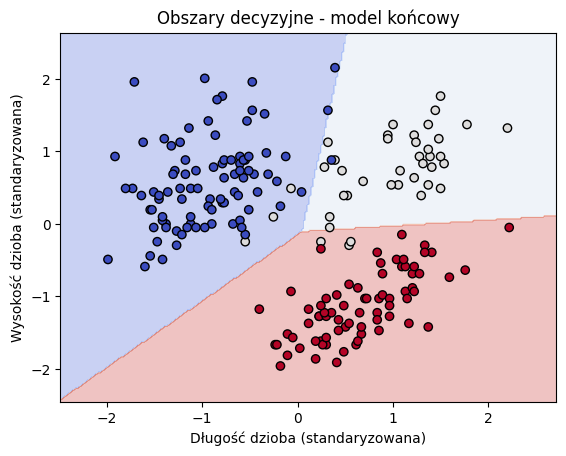

In [48]:
# Twoje rozwiązanie
model_koncowy, _ = train(lr=0.1)
model_koncowy.eval()
with torch.no_grad():
    te_out = model_koncowy(X_te)
    te_preds = torch.argmax(te_out, dim=1)
    acc_test = (te_preds == y_te).float().mean().item()
    p_test = torch.softmax(te_out[:5], dim=1)

sk_model = LogisticRegression(C=1e5, solver="lbfgs")
sk_model.fit(X_tr.numpy(), y_tr.numpy())
acc_sk = sk_model.score(X_te.numpy(), y_te.numpy())

print(f"PyTorch Test Acc: {acc_test:.4f}")
print(f"Sklearn Test Acc: {acc_sk:.4f}")

species_names = ["Adelie", "Chinstrap", "Gentoo"]
print("\nPierwsze 5 obiektów testowych:")
for i in range(5):
    probs = p_test[i].tolist()
    true_class = species_names[y_te[i].item()]
    print(f"Obiekt {i+1}: Prawdopodobieństwa: Adelie={probs[0]:.3f}, Chinstrap={probs[1]:.3f}, Gentoo={probs[2]:.3f} | Prawdziwy gatunek: {true_class}")

def granica(model, X, y):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        Z = torch.argmax(model(grid), dim=1).reshape(xx.shape).numpy()
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors="k")
    plt.xlabel("Długość dzioba (standaryzowana)")
    plt.ylabel("Wysokość dzioba (standaryzowana)")
    plt.title("Obszary decyzyjne - model końcowy")
    plt.show()

granica(model_koncowy, X_tr.numpy(), y_tr.numpy())

In [49]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

1. Model PyTorch wypada niemal indentycznie jak klasyfikator ze sckit-learn. Nie jest to zaskakujące, bo obie biblioteki realizują optymalizację tego samego modelu liniowego z wieloklasowa regresja logistyczną (softmax)
2. Błędy modelu powstają na stykach klas Adelie i Chinstrap, gdzie punkty obu gatunków nakładają się na siebie. Klasyczny model liniowy nie jest w stanie poprawić tego wyniku, poniważ jego graniece decyzyjne to linie proste.
3. optimizer.zero_grad() - czyści gradienty zgromadzone w poprzedniej itreracji

   out = model_loc(b_X) - wykonuje przepływ w przod i wylicza prognozy

   loss = loss_fn_loc(out, b_y) - oblicza wartosci funkcji straty dla biezacej paczki danych

   loss.backward() - oblicza gradienty funkcji straty względem wag modelu za pomocą propagacji wstecznej.

   optimizer.step() - aktualizuje wagi modelu na podstawie obliczonych gradientow

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?